# Task 2 - Multilayer Perceptron (MLP) random search

This notebook narrows the MLP hyperparameter space for Task 2 using
`RandomizedSearchCV`. The best region identified here can be used to define
a smaller grid search in a subsequent experiment.

The workflow is leakage-safe:

1. combine the SNR datasets and keep the SNR as metadata;
2. make one stratified train/validation split;
3. fit standardisation only inside each cross-validation training fold;
4. sample MLP configurations with stratified 5-fold cross-validation on the
   training partition;
5. fit the selected model on all training data and evaluate once on validation
   data;
6. report overall and per-SNR accuracy, precision, recall, and F1 score.

The held-out validation set is not used for model selection.


In [5]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    make_scorer,
)
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier


RANDOM_STATE = 12
TEST_SIZE = 0.20
CV_SPLITS = 5

SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = [
    "Normal",
    "Sag",
    "Swell",
    "Interruption",
    "Harmonics",
    "Sag_harmonics",
    "Swell_harmonics",
    "Transient",
    "Flicker",
]

NORMAL_LABEL = "Normal"
normal_precision_scorer = make_scorer(
    precision_score,
    labels=[NORMAL_LABEL],
    average="macro",
    zero_division=0,
)

# The Task 1 positional convention maps raw columns to the F1-F8 names below.
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {
    "avg abs": "F2",
    "sd": "F3",
    "max": "F4",
    "min": "F5",
    "no. pks": "F6",
    "sd fma": "F7",
    "sd fma 3": "F1",
    "no. pt near 0": "F8",
            }

# Make the notebook independent of the directory from which Jupyter was started.
current = Path.cwd().resolve()
DATA_ROOT = next(
    (path / "Code" / "data" for path in [current, *current.parents]
     if (path / "Code" / "data").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find Code/data. Run this notebook inside the project "
        "repository or update DATA_ROOT."
    )
print(f"Using data from: {DATA_ROOT}")


Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/data


## 1. Load and label all SNR datasets

Each CSV contains one row per signal sample. The filename is the PQD class label;
the first CSV column is an index and is intentionally ignored. SNR is retained
in a separate column so that robustness can be inspected after the final
evaluation.


In [6]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
print(f"Loaded {len(dataset):,} samples and {X.shape[1]} features.")
# display(dataset.groupby(["snr", "label"]).size().unstack(fill_value=0))


Loaded 6,705 samples and 8 features.


## 2. Create a stratified train/validation split

Stratification preserves the class proportions in both partitions. The pipeline
below places `StandardScaler` before the MLP, which is important because the
features have very different numerical scales. The scaler is fitted separately
inside every cross-validation fold and later on the training partition only.


In [7]:
X_train, X_valid, y_train, y_valid, snr_train, snr_valid = train_test_split(
    X,
    y,
    dataset["snr"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_valid):,}")


Training samples: 5,364
Validation samples: 1,341


## 3. Narrow the MLP hyperparameters with random search

The search samples hidden-layer size, activation function, solver, L2
regularisation (`alpha`), and the initial learning rate. Macro-F1 is the
selection metric so that every PQD class contributes equally. The scaler
is inside the pipeline, preventing information from a validation fold from
leaking into its training data.


In [ ]:
param_distributions = {
    "mlp__hidden_layer_sizes": [
        (32,), (64,), (128,),
        (32, 32), (64, 64), (128, 128),
        (32, 64, 32), (64, 128, 64),
        (128, 64, 32),
    ],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    "mlp__learning_rate_init": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
}

search_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "mlp",
            MLPClassifier(
                batch_size=64,
                max_iter=500,
                early_stopping=False,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

cv = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

random_search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=param_distributions,
    n_iter=200,
    scoring={
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro",
        "normal_precision": normal_precision_scorer,
    },
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=False,
)
random_search.fit(X_train, y_train)

random_results = (
    pd.DataFrame(random_search.cv_results_)
    .sort_values("mean_test_f1_macro", ascending=False)
    .reset_index(drop=True)
)
result_columns = [
    "params", "mean_test_accuracy", "mean_test_precision_macro",
    "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "mean_test_normal_precision",
]
display(random_results[result_columns].head(50))
best_params = {
    key.removeprefix("mlp__"): value
    for key, value in random_search.best_params_.items()
}
print("Best cross-validated macro-F1:", random_search.best_score_)
print("Selected configuration:", best_params)


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase t

,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro,std_test_f1_macro,mean_test_normal_precision
0,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.986204,0.986411,0.986204,0.986241,0.000692,0.944781
1,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.986204,0.986366,0.986200,0.986224,0.001910,0.949096
2,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.986204,0.986366,0.986200,0.986224,0.001910,0.949096
3,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.985086,0.985285,0.985082,0.985116,0.001950,0.944657
4,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.984340,0.984626,0.984339,0.984386,0.001894,0.941830
5,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.984153,0.984260,0.984150,0.984138,0.002075,0.951715
6,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.983035,0.983132,0.983039,0.983051,0.001901,0.948664
7,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.983035,0.983234,0.983030,0.983034,0.002119,0.945279
8,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.982849,0.982983,0.982849,0.982867,0.003396,0.940640
9,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.982476,0.982913,0.982468,0.982529,0.002295,0.926665


Best cross-validated macro-F1: 0.9862412761202709
Selected configuration: {'solver': 'adam', 'learning_rate_init': 0.0001, 'hidden_layer_sizes': (64, 128, 64), 'alpha': 0.0001, 'activation': 'tanh'}


## 4. Fit the selected MLP and evaluate on held-out validation data

The following metrics are the final validation results for the configuration
selected by random search. The validation set remains untouched during the
search.


,Metric,Value
0,Accuracy,0.979866
1,Macro precision,0.980402
2,Macro recall,0.979866
3,Macro F1,0.979942
4,Weighted F1,0.979942


,precision,recall,f1-score,support
Normal,0.905660,0.966443,0.935065,149.0
Sag,0.993197,0.979866,0.986486,149.0
Swell,1.000000,1.000000,1.000000,149.0
Interruption,0.980132,0.993289,0.986667,149.0
Harmonics,1.000000,1.000000,1.000000,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.965753,0.946309,0.955932,149.0
Flicker,0.978873,0.932886,0.955326,149.0


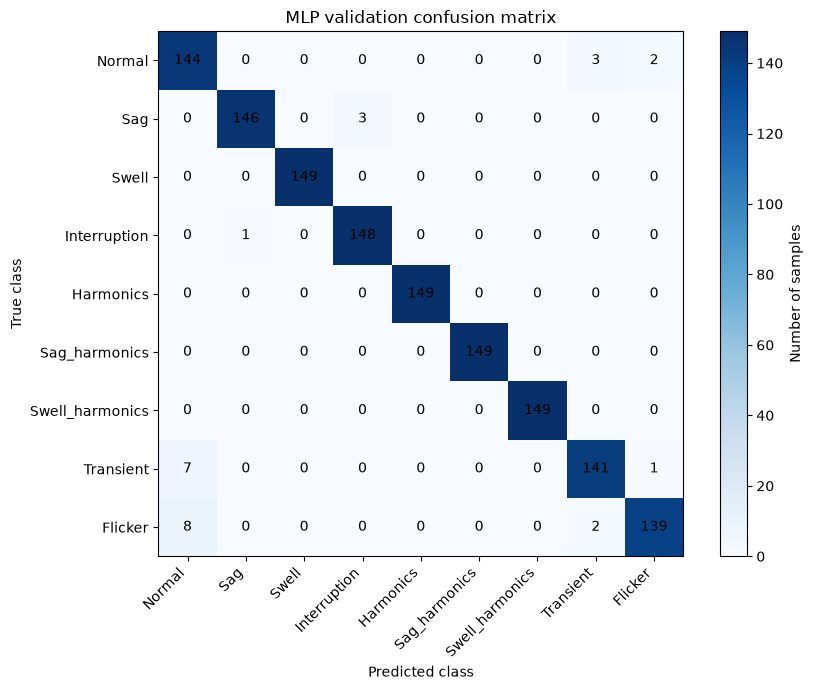

In [9]:
final_model = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "mlp",
            MLPClassifier(
                **best_params,
                batch_size=64,
                max_iter=500,
                early_stopping=False,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_valid)

overall_metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
        "Value": [
            accuracy_score(y_valid, y_pred),
            precision_score(y_valid, y_pred, average="macro", zero_division=0),
            recall_score(y_valid, y_pred, average="macro", zero_division=0),
            f1_score(y_valid, y_pred, average="macro", zero_division=0),
            f1_score(y_valid, y_pred, average="weighted", zero_division=0),
        ],
    }
)
display(overall_metrics)

report = pd.DataFrame(
    classification_report(
        y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0
    )
).T
display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

fig, ax = plt.subplots(figsize=(9, 7))
confusion = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
image = ax.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of samples")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("MLP validation confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Evaluate robustness at each SNR level

This is a diagnostic breakdown of the same held-out validation predictions.
It does not refit the model for each SNR, so the numbers describe how one MLP
trained on the complete range of noise conditions behaves as contamination
increases.


In [10]:
# validation_results = dataset.loc[X_valid.index, ["snr"]].copy()
# validation_results["label"] = y_valid
# validation_results["prediction"] = y_pred

# snr_rows = []
# for snr, group in validation_results.groupby("snr", sort=False):
#     snr_rows.append(
#         {
#             "SNR": snr,
#             "Samples": len(group),
#             "Accuracy": accuracy_score(group["label"], group["prediction"]),
#             "Macro precision": precision_score(
#                 group["label"], group["prediction"], labels=CLASS_NAMES,
#                 average="macro", zero_division=0
#             ),
#             "Macro recall": recall_score(
#                 group["label"], group["prediction"], labels=CLASS_NAMES,
#                 average="macro", zero_division=0
#             ),
#             "Macro F1": f1_score(
#                 group["label"], group["prediction"], labels=CLASS_NAMES,
#                 average="macro", zero_division=0
#             ),
#         }
#     )
# snr_results = pd.DataFrame(snr_rows)
# display(snr_results)

# ax = snr_results.set_index("SNR")[["Accuracy", "Macro F1"]].plot(
#     kind="bar", ylim=(0, 1.05), figsize=(9, 4), rot=0
# )
# ax.set_ylabel("Score")
# ax.set_title("MLP performance by SNR")
# ax.grid(axis="y", alpha=0.3)
# plt.tight_layout()
# plt.show()


## Interpretation

Use the cross-validation table to justify the selected architecture and use the
validation metrics, class report, confusion matrix, and SNR table to discuss
effectiveness. For the full Task 2 submission, this MLP should be compared with
the Decision Tree and Random Forest classifiers using the same split and metric
definitions. A higher macro-F1 indicates better balanced multiclass recognition.
